# Model 3: Predicting NFL Career Value with XGBoost
**IST 707 — NFL Combine Project | Jacob Sciamanna | Midterm, October 2026**

## Research question
Do combine measurements help predict a drafted player's NFL career value, especially after accounting for draft position?

NFL scouting departments and front offices invest time and resources in athletic testing. A useful model could help them judge whether those measurements add predictive information beyond the draft evaluation process. This is an analysis of historical associations, **not** a replacement for film study or a tool that establishes causation.

XGBoost builds trees sequentially to correct earlier prediction errors. I used it to test whether a more flexible model could capture patterns missed by our decision-tree/random-forest baseline. The goal at this checkpoint is a reproducible comparison, not a fully deployed scouting model.

## 1. Data and outcome
The team's merged dataset combines NFL Combine results, draft information, and Pro Football Reference career Approximate Value. I restrict the modeling sample to drafted players from 2000–2025, excluding specialists.

**Outcome:** `wav_pct` is each player's percentile in weighted career Approximate Value (`w_av`) within his draft class. A score of 80 means he ranks above roughly 80% of that class. This makes classes more comparable, although recent players still have incomplete careers.

**Three feature sets:** combine measurements only; draft pick only; and both together. Position indicators are included in all three because a forty time has different meaning for different positions.

Career statistics and awards are never predictors: they would leak information from after the draft.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
SEED = 42
print('Libraries loaded')

Libraries loaded


In [2]:
URL = 'https://raw.githubusercontent.com/JSciamanna17/IST-707-Final-Project-JS-JH-BW-MM/main/nfl_combine_career_data.csv'
local = Path('nfl_combine_career_data.csv')
raw = pd.read_csv(local if local.exists() else URL)
print('Raw shape:', raw.shape)
display(raw.head(3))

Raw shape: (7437, 53)


,season.x,draft_year,draft_team,draft_round,draft_ovr,pfr_id,cfb_id,player_name,pos,school,...,pass_ints,rush_atts,rush_yards,rush_tds,receptions,rec_yards,rec_tds,def_solo_tackles,def_ints,def_sacks
0,2000,2000.0,New York Jets,1.0,13.0,AbraJo00,NaN,John Abraham,OLB,South Carolina,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,463.0,1.0,133.5
1,2000,2000.0,Seattle Seahawks,1.0,19.0,AlexSh00,shaun-alexander-1,Shaun Alexander,RB,Alabama,...,0.0,2187.0,9453.0,100.0,215.0,1520.0,12.0,NaN,NaN,NaN
2,2000,2000.0,Kansas City Chiefs,6.0,188.0,AlfoDa20,NaN,Darnell Alford,OT,Boston Col.,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN


## 2. Prepare the modeling sample
I follow the same position groupings, target definition, and 80/20 stratified split as the random forest notebook so the results can be compared directly. I calculate class percentiles before excluding specialists, matching the team's existing method.

Players who skipped a drill retain missing values; XGBoost can handle these directly. I do not fill in guessed results.

In [3]:
df = raw.copy()
def ht_to_in(h):
    try:
        feet, inches = str(h).split('-')
        return int(feet)*12 + int(inches)
    except (ValueError, TypeError):
        return np.nan
POS_MAP = {'QB':'QB','RB':'RB','FB':'RB','WR':'WR','TE':'TE',
           'OT':'OL','OG':'OL','C':'OL','OL':'OL','G':'OL',
           'DT':'DL','DL':'DL','DE':'EDGE','EDGE':'EDGE',
           'ILB':'LB','OLB':'LB','LB':'LB',
           'CB':'CB','DB':'CB','S':'S','SAF':'S'}
df['ht_in'] = df['ht'].apply(ht_to_in)
df['pos_group'] = df['pos'].map(POS_MAP)
df['pick_num'] = df['pick'].fillna(df['draft_ovr'])
df['draft_class'] = df['season.x']
df = df[df['w_av'].notna() & df['pick_num'].notna() & (df['draft_class'] <= 2025)].copy()
df['wav_pct'] = df.groupby('draft_class')['w_av'].rank(pct=True)*100
df = df[df['pos_group'].notna()].copy()
COMBINE = ['ht_in','wt','forty','bench','vertical','broad_jump','cone','shuttle']
DRAFT = ['pick_num']
TARGET = 'wav_pct'
POS_COLS = list(pd.get_dummies(df['pos_group'], prefix='pos', dtype=int).columns)
data = pd.concat([df, pd.get_dummies(df['pos_group'], prefix='pos', dtype=int)], axis=1)
train_df, test_df = train_test_split(data, test_size=.2, random_state=SEED, stratify=data['pos_group'])
print('Modeling rows:',len(df),'Train:',len(train_df),'Test:',len(test_df))
print('Missing drill fractions:'); display(df[COMBINE].isna().mean().round(3))

Modeling rows: 5098 Train: 4078 Test: 1020
Missing drill fractions:


,0
ht_in,0.003
wt,0.003
forty,0.081
bench,0.358
vertical,0.217
broad_jump,0.228
cone,0.410
shuttle,0.393


## 3. Establish a null baseline
A mean-only model predicts the average training-set percentile for everyone. If XGBoost cannot improve on this, it is not providing useful predictive information. Five-fold cross-validation is performed on training data only.

In [4]:
FEATURE_SETS = {'Combine only': COMBINE, 'Draft only': DRAFT, 'Combine + Draft': COMBINE+DRAFT}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
ytr = train_df[TARGET]
null = DummyRegressor(strategy='mean')
null_cv = cross_validate(null, train_df[POS_COLS], ytr, cv=cv,
                         scoring={'r2':'r2','mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error'})
print('Null 5-fold CV R²:',round(null_cv['test_r2'].mean(),3))
print('Null 5-fold CV RMSE:',round(-null_cv['test_rmse'].mean(),2))

Null 5-fold CV R²: -0.002
Null 5-fold CV RMSE: 28.85


## 4. Initial XGBoost comparison
I first use the same reasonable starting settings for all three feature sets. Cross-validation measures whether a model generalizes beyond the players it was trained on.

In [5]:
def xgb_model(**kw):
    return XGBRegressor(objective='reg:squarederror', random_state=SEED,
                        tree_method='hist', n_jobs=2, **kw)
initial = []
for name, cols in FEATURE_SETS.items():
    model = xgb_model(n_estimators=250, max_depth=3, learning_rate=.05,
                      subsample=.8, colsample_bytree=.9, reg_lambda=5)
    scores = cross_validate(model, train_df[cols+POS_COLS], ytr, cv=cv,
                            scoring={'r2':'r2','rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error'})
    initial.append({'Features':name,'CV_R2':scores['test_r2'].mean(),
                    'CV_RMSE':-scores['test_rmse'].mean(),'CV_MAE':-scores['test_mae'].mean()})
initial_table = pd.DataFrame(initial)
display(initial_table.round(3))

,Features,CV_R2,CV_RMSE,CV_MAE
0,Combine only,0.045,28.160,24.066
1,Draft only,0.323,23.710,19.599
2,Combine + Draft,0.324,23.701,19.551


## 5. Tune model complexity
I tune each feature set separately because a model with only draft pick may need different settings than one with many measurements. The search adjusts tree depth, learning rate, number of trees, row/column sampling, and regularization. All tuning happens within the training set.

In [6]:
space = {'n_estimators':[100,200,400], 'max_depth':[2,3,4],
         'learning_rate':[.02,.05,.1], 'subsample':[.75,1.0],
         'colsample_bytree':[.75,1.0], 'min_child_weight':[5,15],
         'reg_lambda':[1,5,15]}
tuned = {}; tuning_rows=[]
for name, cols in FEATURE_SETS.items():
    search = RandomizedSearchCV(xgb_model(), space, n_iter=12, scoring='r2',
                                cv=cv, random_state=SEED, n_jobs=2, refit=True)
    search.fit(train_df[cols+POS_COLS], ytr)
    tuned[name] = search.best_estimator_
    tuning_rows.append({'Features':name,'CV_R2':search.best_score_, 'Best_params':search.best_params_})
    print(name, 'CV R²:', round(search.best_score_,3), 'params:',search.best_params_)
display(pd.DataFrame(tuning_rows))

Combine only CV R²: 0.05 params: {'subsample': 0.75, 'reg_lambda': 15, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Draft only CV R²: 0.326 params: {'subsample': 0.75, 'reg_lambda': 15, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.75}
Combine + Draft CV R²: 0.325 params: {'subsample': 0.75, 'reg_lambda': 15, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


,Features,CV_R2,Best_params
0,Combine only,0.049640,"{'subsample': 0.75, 'reg_lambda': 15, 'n_estim..."
1,Draft only,0.325600,"{'subsample': 0.75, 'reg_lambda': 15, 'n_estim..."
2,Combine + Draft,0.325224,"{'subsample': 0.75, 'reg_lambda': 15, 'n_estim..."


## 6. Compare predictions on the held-out test set
After selecting hyperparameters, I evaluate each model on the same untouched 20% of players. **R²** measures explained variation (0 is roughly the mean-only benchmark); **RMSE** and **MAE** express error in percentile points. Smaller errors are better.

In [7]:
results=[]
null.fit(train_df[POS_COLS],ytr)
models = {'Null mean':(null,POS_COLS)}
models.update({name:(tuned[name], cols+POS_COLS) for name,cols in FEATURE_SETS.items()})
for name,(model,cols) in models.items():
    pred = model.predict(test_df[cols])
    results.append({'Model':name,'Test_R2':r2_score(test_df[TARGET],pred),
                    'Test_RMSE':np.sqrt(mean_squared_error(test_df[TARGET],pred)),
                    'Test_MAE':mean_absolute_error(test_df[TARGET],pred)})
results_df = pd.DataFrame(results)
display(results_df.round(3))
print('Model 1 RF reference (from teammate notebook): Combine .078; Draft .322; Both .324 test R²')

,Model,Test_R2,Test_RMSE,Test_MAE
0,Null mean,-0.000,29.107,25.235
1,Combine only,0.082,27.884,23.993
2,Draft only,0.331,23.800,19.598
3,Combine + Draft,0.329,23.845,19.513


Model 1 RF reference (from teammate notebook): Combine .078; Draft .322; Both .324 test R²


### Results from the October 15 run

| Model | Test R² | Test RMSE | Test MAE |
|---|---:|---:|---:|
| Mean-only baseline | -0.000 | 29.107 | 25.235 |
| Combine only | 0.082 | 27.884 | 23.993 |
| Draft only | **0.331** | **23.800** | 19.598 |
| Combine + draft | 0.329 | 23.845 | **19.513** |

The draft-only model had the highest test R² and lowest RMSE. Adding combine results slightly lowered MAE, but did not meaningfully improve overall fit. Combine measurements alone explained about 8% of the variation in the target.

The team's random forest test R² values were 0.078 (combine), 0.322 (draft), and 0.324 (both). XGBoost is slightly higher on this split, but these differences are too small to claim a reliable advantage without further testing. The cross-validated XGBoost R² scores after tuning were approximately 0.050, 0.326, and 0.325, respectively.

## 7. Presentation figures
These charts focus on the main comparison, the size of prediction errors, and which features the combined model relies on. The same test set is used throughout. Figures are saved as high-resolution PNGs for the slides.


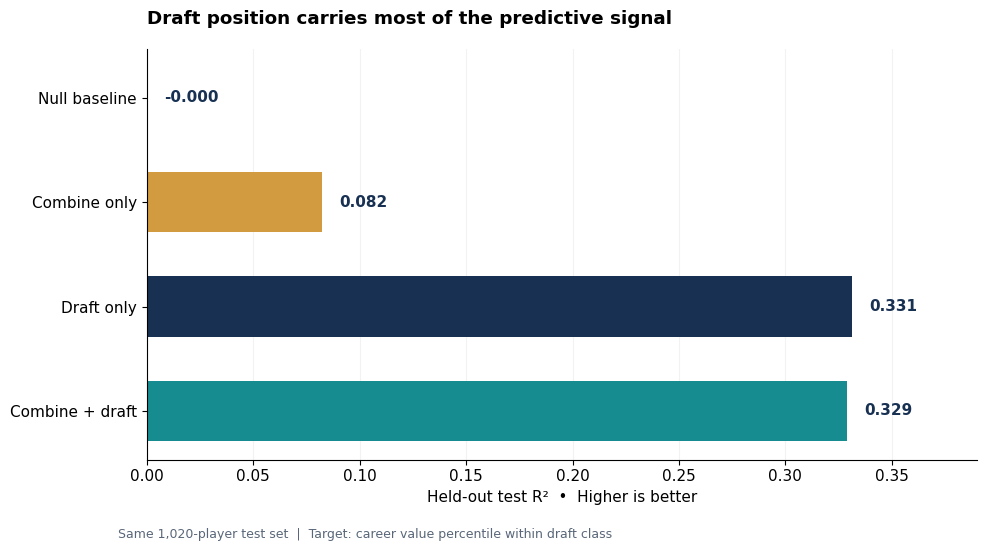

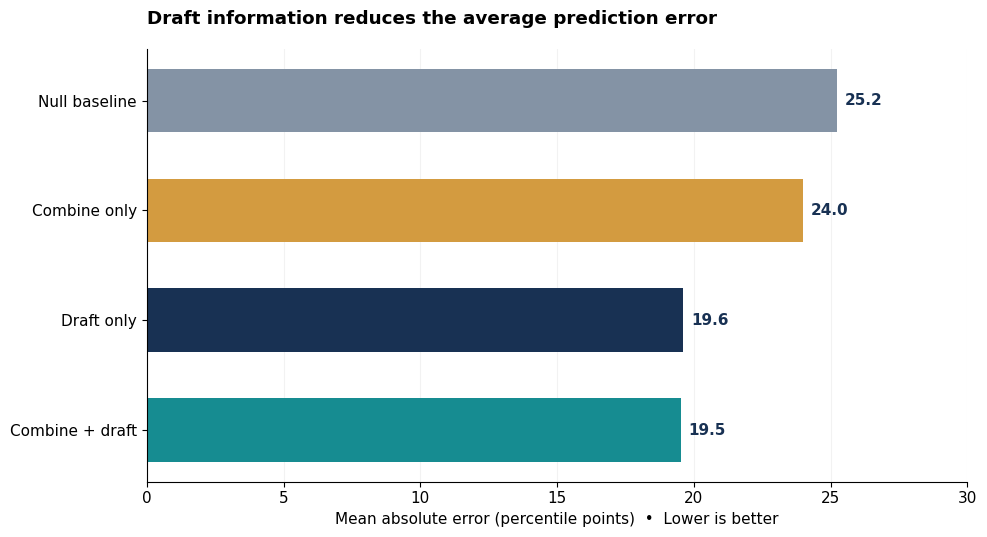

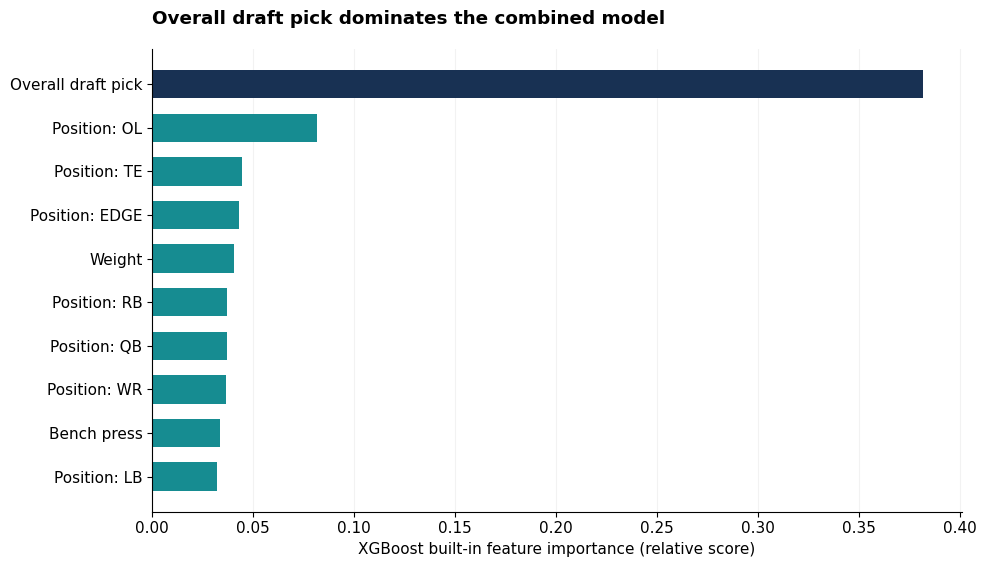

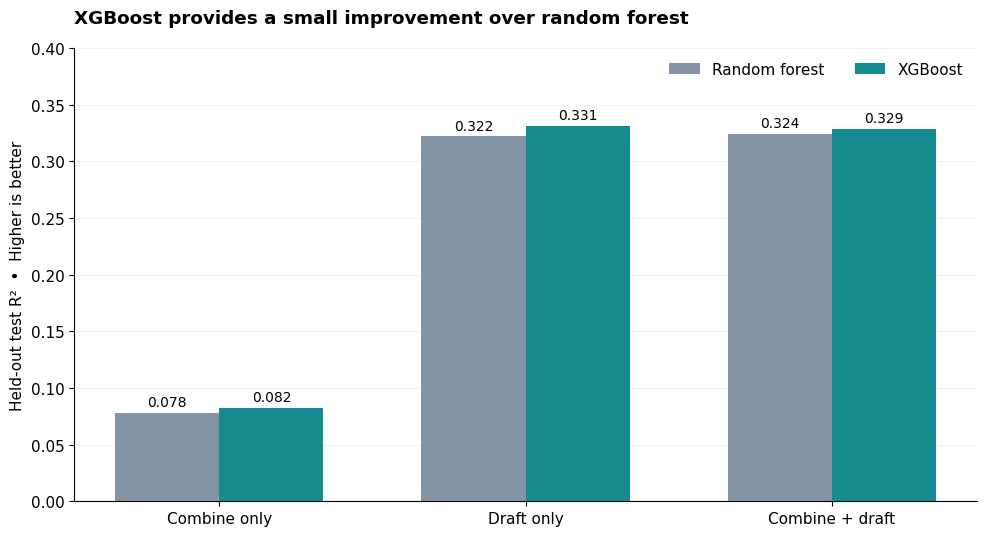

In [8]:
from matplotlib.ticker import MultipleLocator

# Consistent formatting makes the figures easier to compare on slides.
NAVY = '#183153'
TEAL = '#168C91'
GOLD = '#D39B40'
SLATE = '#8493A5'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'figure.facecolor':'white',
                     'axes.facecolor':'white', 'savefig.facecolor':'white'})

def finish_chart(fig, filename):
    fig.savefig(filename, dpi=220, bbox_inches='tight', facecolor='white')
    plt.show()

# Chart 1: Compare each information source with a mean-only prediction.
plot = results_df.set_index('Model').loc[['Null mean','Combine only','Draft only','Combine + Draft']]
labels = ['Null baseline','Combine only','Draft only','Combine + draft']
colors = [SLATE, GOLD, NAVY, TEAL]
fig, ax = plt.subplots(figsize=(10,5.5))
bars = ax.barh(labels, plot['Test_R2'].clip(lower=0), color=colors, height=.58)
ax.invert_yaxis()
ax.set_xlim(0,.39)
ax.set_xlabel('Held-out test R²  •  Higher is better')
ax.set_title('Draft position carries most of the predictive signal', loc='left', pad=18)
ax.grid(axis='x', alpha=.16)
ax.set_axisbelow(True)
for bar, value in zip(bars, plot['Test_R2']):
    ax.text(max(bar.get_width(),0)+.008, bar.get_y()+bar.get_height()/2,
            f'{value:.3f}', va='center', fontweight='bold', color=NAVY)
fig.text(.125,.01,'Same 1,020-player test set  |  Target: career value percentile within draft class',
         fontsize=9, color='#596779')
fig.tight_layout(rect=[0,.04,1,1])
finish_chart(fig,'xgb_model_comparison.png')

# Chart 2: Translate model performance into typical prediction error.
fig, ax = plt.subplots(figsize=(10,5.5))
bars = ax.barh(labels, plot['Test_MAE'], color=colors, height=.58)
ax.invert_yaxis()
ax.set_xlim(0,30)
ax.set_xlabel('Mean absolute error (percentile points)  •  Lower is better')
ax.set_title('Draft information reduces the average prediction error', loc='left', pad=18)
ax.grid(axis='x', alpha=.16)
ax.set_axisbelow(True)
for bar, value in zip(bars, plot['Test_MAE']):
    ax.text(value+.3,bar.get_y()+bar.get_height()/2,f'{value:.1f}',va='center',fontweight='bold',color=NAVY)
fig.tight_layout()
finish_chart(fig,'xgb_prediction_error.png')

# Chart 3: Built-in feature importance from the combined model.
# These scores describe how the model uses features, not causal effects.
model = tuned['Combine + Draft']
cols = FEATURE_SETS['Combine + Draft'] + POS_COLS
importance = pd.Series(model.feature_importances_,index=cols).sort_values(ascending=False).head(10)
readable = {'pick_num':'Overall draft pick','wt':'Weight','ht_in':'Height',
            'forty':'40-yard dash','bench':'Bench press','vertical':'Vertical jump',
            'broad_jump':'Broad jump','cone':'3-cone drill','shuttle':'Shuttle drill'}
feature_labels = [readable.get(x,x.replace('pos_','Position: ')) for x in importance.index]
fig, ax = plt.subplots(figsize=(10,5.8))
bars = ax.barh(feature_labels[::-1],importance.values[::-1],
               color=[NAVY if x=='pick_num' else TEAL for x in importance.index[::-1]],height=.65)
ax.set_xlabel('XGBoost built-in feature importance (relative score)')
ax.set_title('Overall draft pick dominates the combined model',loc='left',pad=18)
ax.grid(axis='x',alpha=.16)
ax.set_axisbelow(True)
fig.tight_layout()
finish_chart(fig,'xgb_feature_importance.png')

# Chart 4: Compare XGBoost with the random forest results reported by the team.
rf = [.078,.322,.324]
xgb = plot.loc[['Combine only','Draft only','Combine + Draft'],'Test_R2'].values
names = ['Combine only','Draft only','Combine + draft']
x = np.arange(len(names)); width=.34
fig, ax = plt.subplots(figsize=(10,5.5))
a = ax.bar(x-width/2,rf,width,label='Random forest',color=SLATE)
b = ax.bar(x+width/2,xgb,width,label='XGBoost',color=TEAL)
for bars in (a,b):
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.006,
                f'{bar.get_height():.3f}',ha='center',fontsize=10)
ax.set_xticks(x,names)
ax.set_ylim(0,.40)
ax.set_ylabel('Held-out test R²  •  Higher is better')
ax.set_title('XGBoost provides a small improvement over random forest',loc='left',pad=18)
ax.legend(frameon=False,ncol=2)
ax.grid(axis='y',alpha=.16)
ax.set_axisbelow(True)
fig.tight_layout()
finish_chart(fig,'xgb_vs_random_forest.png')


## 8. Interpretation and project implications
**Who benefits?** NFL scouting and personnel analysts could use this comparison to assess whether standardized athletic testing provides additional predictive value beyond the team's overall draft evaluation. Analysts studying the draft also benefit from a reproducible benchmark for how much signal different information sources carry.

**What we found:** Draft position was much more informative than combine testing alone. This is consistent with draft picks already reflecting many sources of evaluation, possibly including combine results, but our models cannot isolate why.

**Challenges:** Some players skip drills; recent draft classes have incomplete career histories; performance differs by position; and the analysis covers drafted players only. A random player split also differs from forecasting an entirely future draft class.

**Next steps for the final:** Repeat the comparison using 2000–2019 classes, test a chronological holdout, examine RB/OL/TE separately, and check whether the small differences persist across repeated splits. These tests matter more than squeezing another decimal point out of one test set.

**Presentation takeaway:** A more complex model did not change the main conclusion: draft position predicts class-adjusted career value substantially better than combine measurements, and combine data adds little once draft position is known.

## 8. Exploratory checks: what the data looks like

Before interpreting model performance, I check the target distribution, sample sizes by position, missing drill results, and relationships between draft pick, speed, and career value. The missingness plot matters because players do not all participate in every drill; that can affect what the model learns.


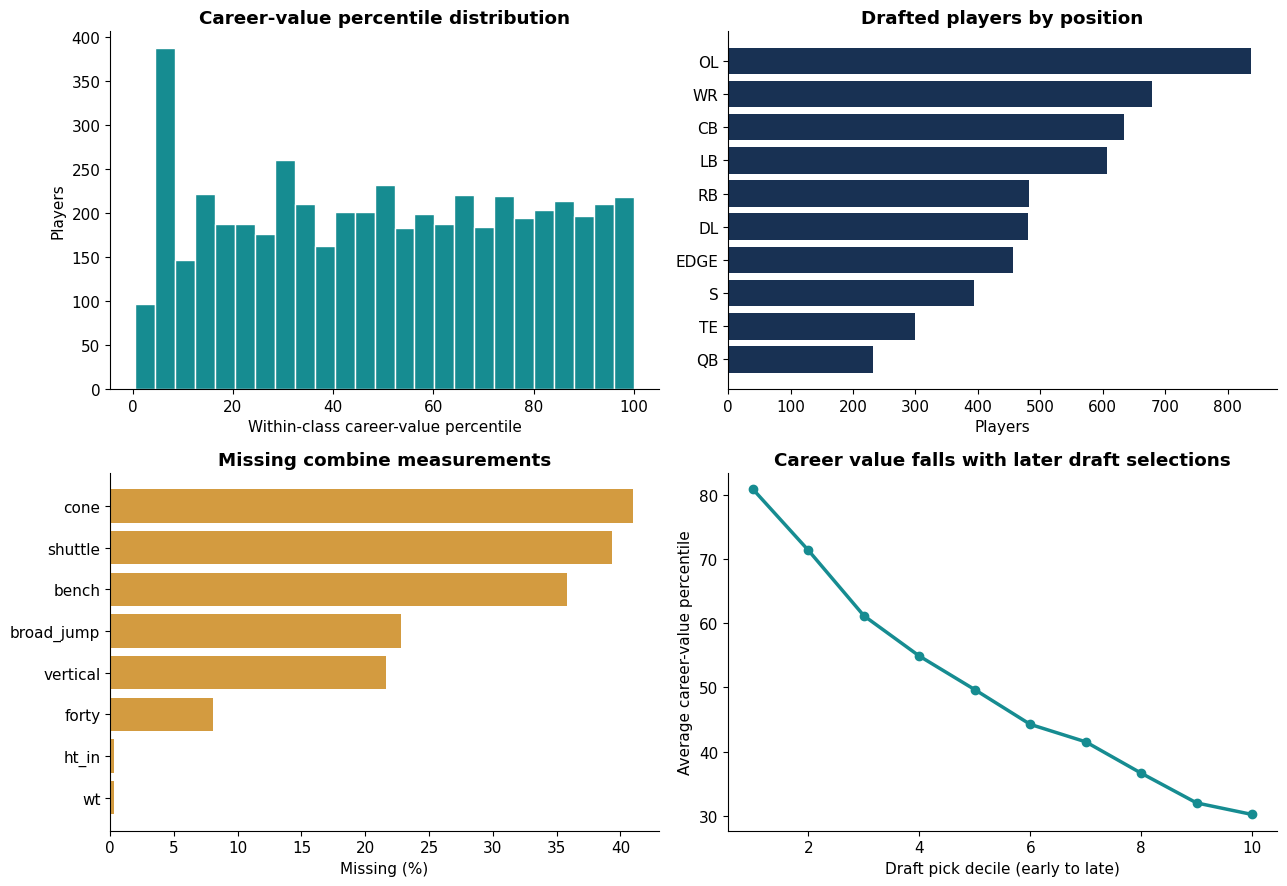

Spearman correlation: draft pick vs career-value percentile: -0.545
Spearman correlation: 40 time vs career-value percentile: 0.03


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].hist(df[TARGET], bins=25, color=TEAL, edgecolor='white')
axes[0,0].set(title='Career-value percentile distribution', xlabel='Within-class career-value percentile', ylabel='Players')
counts = df['pos_group'].value_counts().sort_values()
axes[0,1].barh(counts.index, counts.values, color=NAVY)
axes[0,1].set(title='Drafted players by position', xlabel='Players')
missing = df[COMBINE].isna().mean().sort_values()
axes[1,0].barh(missing.index, missing.values*100, color=GOLD)
axes[1,0].set(title='Missing combine measurements', xlabel='Missing (%)')
by_pick = df.groupby(pd.qcut(df['pick_num'], 10, duplicates='drop'), observed=True)[TARGET].mean()
axes[1,1].plot(range(1,len(by_pick)+1), by_pick.values, marker='o', color=TEAL, linewidth=2.5)
axes[1,1].set(title='Career value falls with later draft selections', xlabel='Draft pick decile (early to late)', ylabel='Average career-value percentile')
for ax in axes.flat: ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('xgb_eda_overview.png', dpi=220, bbox_inches='tight'); plt.show()
print('Spearman correlation: draft pick vs career-value percentile:', round(df[['pick_num',TARGET]].corr(method='spearman').iloc[0,1],3))
print('Spearman correlation: 40 time vs career-value percentile:', round(df[['forty',TARGET]].corr(method='spearman').iloc[0,1],3))


## 9. Position-specific XGBoost

The overall results might hide differences between positions. A 40-yard dash may mean something different for a running back than an offensive lineman. I compare the same three feature sets within each position using five-fold cross-validation. These are exploratory results; small position groups can have noisy scores. I reuse the overall tuned settings rather than tuning on the evaluation folds.


Feature sets evaluated: ['Combine only', 'Draft only', 'Combine + Draft']


Features,Combine + Draft,Combine only,Draft only,Gain from combine
Position,,,,
RB,0.313,0.057,0.288,0.025
OL,0.284,0.034,0.303,-0.019
CB,0.255,-0.031,0.282,-0.027
LB,0.248,-0.040,0.303,-0.055
EDGE,0.132,-0.062,0.212,-0.080
WR,0.252,-0.065,0.279,-0.027
S,0.203,-0.067,0.216,-0.012
DL,0.162,-0.077,0.211,-0.050
TE,0.276,-0.155,0.311,-0.036


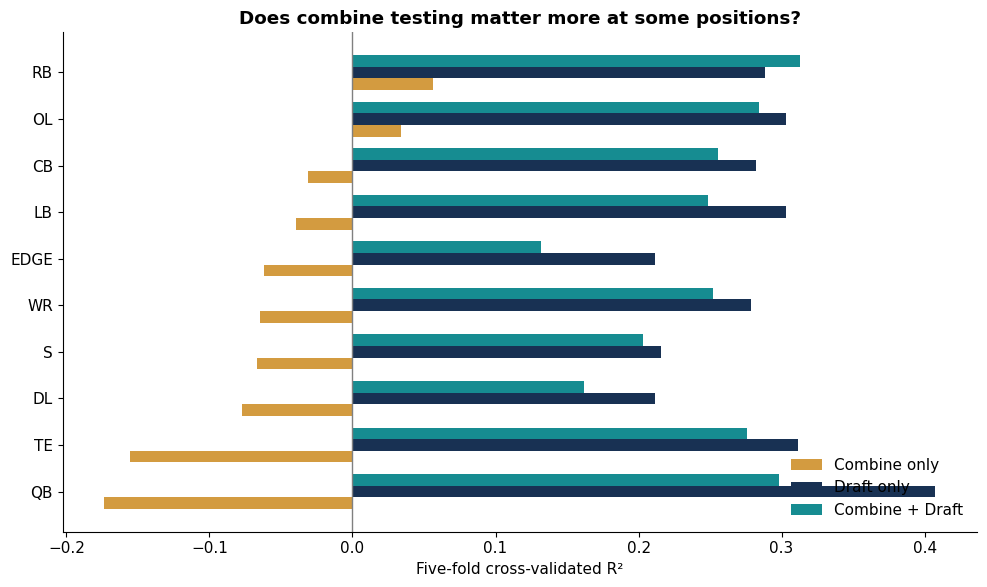

In [13]:
from sklearn.base import clone

position_rows = []
for pos, sub in df.groupby('pos_group'):
    if len(sub) < 75:
        continue
    for name, cols in FEATURE_SETS.items():
        model = clone(tuned[name])
        scores = cross_val_score(model, sub[cols], sub[TARGET], scoring='r2', cv=cv, n_jobs=1)
        position_rows.append({'Position': pos, 'N': len(sub), 'Features': name,
                              'CV_R2': scores.mean(), 'CV_SD': scores.std()})

position_results = pd.DataFrame(position_rows)
print('Feature sets evaluated:', position_results['Features'].unique().tolist())
expected = list(FEATURE_SETS.keys())
missing = set(expected) - set(position_results['Features'])
if missing:
    raise ValueError(f'Missing feature sets: {missing}. Check FEATURE_SETS and rerun this cell.')

position_pivot = position_results.pivot(index='Position', columns='Features', values='CV_R2')
position_pivot['Gain from combine'] = position_pivot['Combine + Draft'] - position_pivot['Draft only']
display(position_pivot.round(3).sort_values('Combine only', ascending=False))

plot = position_pivot.sort_values('Combine only')
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(plot))
h = .25
for j, (name, color) in enumerate([('Combine only', GOLD), ('Draft only', NAVY), ('Combine + Draft', TEAL)]):
    ax.barh(y + (j-1)*h, plot[name], height=h, label=name, color=color)
ax.set_yticks(y, plot.index)
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='Five-fold cross-validated R²', title='Does combine testing matter more at some positions?')
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('xgb_by_position.png', dpi=220, bbox_inches='tight')
plt.show()


## 10. Which individual drills show a signal?

To avoid interpreting feature importance as proof of predictive value, I test each drill by itself within each position. Only players who completed that measurement are included. The models are deliberately shallow, and I leave out groups with fewer than 60 participants. Negative R² means a drill does worse than a simple mean prediction in those folds.


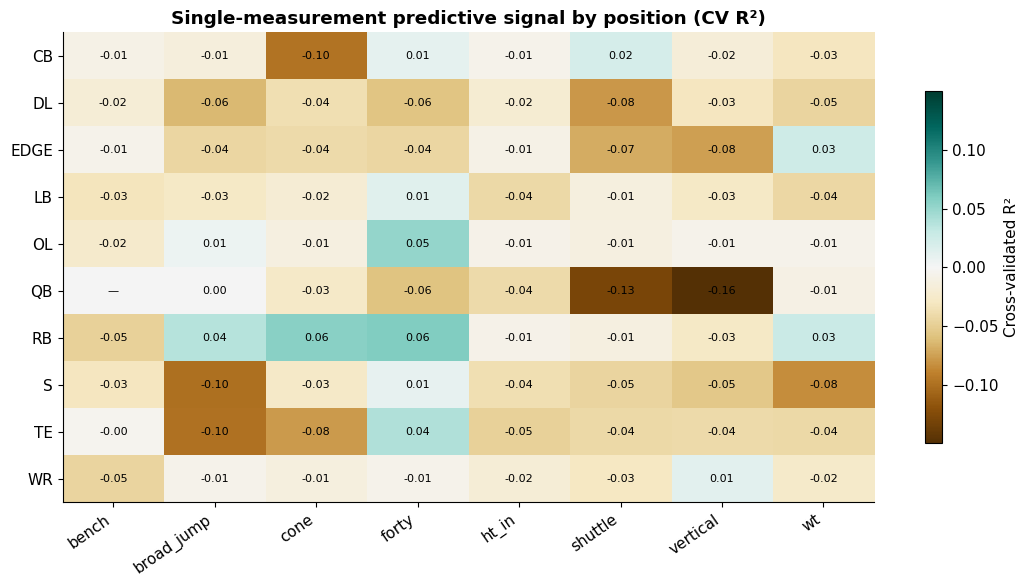

,Position,Drill,N,CV_R2
49,RB,forty,454,0.059
53,RB,cone,259,0.056
34,OL,forty,764,0.051
65,TE,forty,269,0.039
52,RB,broad_jump,391,0.037
48,RB,wt,481,0.027
17,EDGE,wt,456,0.025
7,CB,shuttle,361,0.021
26,LB,forty,559,0.014
75,WR,vertical,543,0.012


In [14]:
drill_rows=[]
for pos,sub in df.groupby('pos_group'):
    for drill in COMBINE:
        done=sub.dropna(subset=[drill]);
        if len(done)<60: continue
        model=xgb_model(n_estimators=100,max_depth=2,learning_rate=.05,min_child_weight=20,reg_lambda=15)
        score=cross_val_score(model,done[[drill]],done[TARGET],cv=cv,scoring='r2',n_jobs=1).mean()
        drill_rows.append({'Position':pos,'Drill':drill,'N':len(done),'CV_R2':score})
drill_results=pd.DataFrame(drill_rows)
heat=drill_results.pivot(index='Position',columns='Drill',values='CV_R2')
fig,ax=plt.subplots(figsize=(11,6))
from matplotlib.colors import TwoSlopeNorm
im=ax.imshow(heat.fillna(0).values,aspect='auto',cmap='BrBG',norm=TwoSlopeNorm(vcenter=0,vmin=-.15,vmax=.15))
ax.set_xticks(range(len(heat.columns)),heat.columns,rotation=35,ha='right')
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_title('Single-measurement predictive signal by position (CV R²)')
for i in range(len(heat.index)):
 for j in range(len(heat.columns)):
    v=heat.iloc[i,j]
    ax.text(j,i,'—' if pd.isna(v) else f'{v:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax,label='Cross-validated R²',shrink=.75)
plt.tight_layout();plt.savefig('xgb_drill_heatmap.png',dpi=220,bbox_inches='tight');plt.show()
display(drill_results.sort_values('CV_R2',ascending=False).head(12).round(3))


## 11. Robustness check: older draft classes

Recent draftees have not had full careers. Ranking players within each draft class helps with the comparison but does not completely solve the problem of incomplete career outcomes. I repeat the three-feature-set comparison for players drafted from 2000 through 2019. This is an additional exploratory five-fold CV analysis, not a new held-out test result.


In [18]:
# Check whether results hold for older draft classes with more complete careers.
from sklearn.base import clone

mature = df[df['draft_class'] <= 2019].copy()
mature_rows = []

for name, cols in FEATURE_SETS.items():
    model = clone(tuned[name])

    X = pd.concat([
        mature[cols],
        pd.get_dummies(mature['pos_group'], prefix='pos', dtype=int)
    ], axis=1)

    # Keep the same feature columns used in the full dataset.
    X = X.reindex(columns=cols + POS_COLS, fill_value=0)

    scores = cross_val_score(
        model,
        X,
        mature[TARGET],
        scoring='r2',
        cv=cv,
        n_jobs=1
    )

    mature_rows.append({
        'Features': name,
        'CV_R2': scores.mean(),
        'CV_SD': scores.std()
    })

mature_results = pd.DataFrame(mature_rows)

print("XGBoost Results: Draft Classes 2000–2019")
print("Players included:", len(mature))

display(mature_results.round(3))

# Compare the mature draft classes with the full dataset.
full_results = pd.DataFrame({
    'Features': [
        'Combine only',
        'Draft only',
        'Combine + Draft'
    ],
    'CV_R2_Full': [
        0.049640,
        0.325600,
        0.325224
    ]
})

comparison = mature_results.merge(
    full_results,
    on='Features'
)

comparison = comparison.rename(
    columns={'CV_R2': 'CV_R2_Mature'}
)

comparison['Difference'] = (
    comparison['CV_R2_Mature'] -
    comparison['CV_R2_Full']
)

display(comparison.round(3))

XGBoost Results: Draft Classes 2000–2019
Players included: 3893


,Features,CV_R2,CV_SD
0,Combine only,0.065,0.011
1,Draft only,0.317,0.023
2,Combine + Draft,0.317,0.024


,Features,CV_R2_Mature,CV_SD,CV_R2_Full,Difference
0,Combine only,0.065,0.011,0.050,0.016
1,Draft only,0.317,0.023,0.326,-0.009
2,Combine + Draft,0.317,0.024,0.325,-0.008


## 12. Diagnostics: where predictions miss

A good overall R² does not guarantee that predictions are accurate for every player. This plot checks whether the combined model systematically misses players at the top or bottom of the career-value distribution. Because this is the held-out test set, it is a diagnostic rather than a reason to keep tuning against these same players.


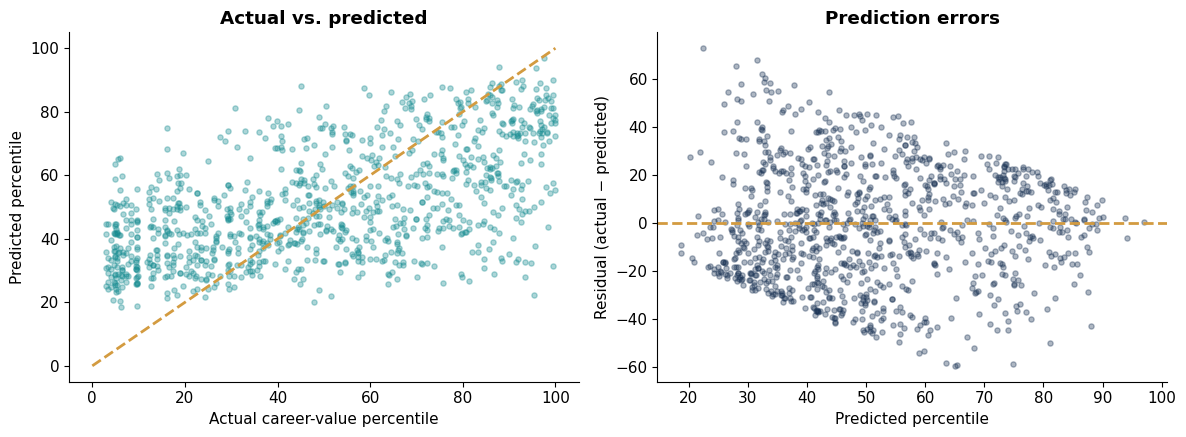

In [19]:
best=tuned['Combine + Draft']
cols=FEATURE_SETS['Combine + Draft']+POS_COLS
pred=best.predict(test_df[cols]); actual=test_df[TARGET].to_numpy()
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(actual,pred,s=14,alpha=.35,color=TEAL)
axes[0].plot([0,100],[0,100],ls='--',color=GOLD,lw=2)
axes[0].set(xlabel='Actual career-value percentile',ylabel='Predicted percentile',title='Actual vs. predicted')
axes[1].scatter(pred,actual-pred,s=14,alpha=.35,color=NAVY)
axes[1].axhline(0,ls='--',color=GOLD,lw=2)
axes[1].set(xlabel='Predicted percentile',ylabel='Residual (actual − predicted)',title='Prediction errors')
for ax in axes:ax.spines[['top','right']].set_visible(False)
plt.tight_layout();plt.savefig('xgb_diagnostics.png',dpi=220,bbox_inches='tight');plt.show()


## 13. What these analyses contribute

The overall comparison addresses the main question: does athletic testing add predictive information beyond draft position? The position-specific and drill-by-drill checks ask whether the overall answer hides useful exceptions. The older-class check tests whether the result is sensitive to incomplete careers, while the residual plots show where the model struggles.

**Who could use this?** NFL scouting and player-personnel departments can use evidence like this to decide how much weight to place on standardized athletic testing alongside draft grades and film evaluation. College recruiting and player-development staff may also find position-specific patterns useful. These results are associations, not evidence that changing a player's drill time causes greater career value.
